In [ ]:
import pickle
import time
from dataclasses import dataclass
from datetime import datetime
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

from mlkit.blocks.activations import LeakyReLU, Tanh
from mlkit.blocks.conv import ConvBlockConfig, ConvTransposeBlockConfig
from mlkit.blocks.linear import LinearBlockConfig
from mlkit.blocks.norms import BatchNorm
from mlkit.core.callbacks import MLflowLogger, ProgressLogger
from mlkit.core.history import History
from mlkit.core.trainer import Trainer
from mlkit.models.cnn_classifier import CNNClassifier, CNNConfig
from mlkit.models.generator import Generator, GeneratorConfig
from mlkit.tasks.gan import GANTask
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.utils.tracking import flatten_params, setup_mlflow
from mlkit.visual.curves import plot_comparison
from mlkit.visual.images import plot_image_grid
from mlkit.visual.samples import SampleGrid
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

import mlflow

setup_logging()
use_style()

ROOT = Path("../..")
DATA_PATH = ROOT / "datasets/raw/GTSRB/train.p"
setup_mlflow(ROOT, "lab2.2")

SEED = 42
BATCH_SIZE = 128
EPOCHS = 50
LATENT_DIM = 100
LEARNING_RATE = 2e-4
BETAS = (0.5, 0.999)
REAL_LABEL = 0.9
SAMPLE_EVERY = 5
NUM_SAMPLES = 32

RUN_NAME = f"lab2.2_{datetime.now():%Y%m%d_%H%M%S}"
saver = FigureSaver(Path("artifacts") / RUN_NAME)

In [15]:
with open(DATA_PATH, "rb") as file:
    raw = pickle.load(file)

features: np.ndarray = raw["features"]
labels: np.ndarray = raw["labels"]
class_counts = pd.Series(labels).value_counts().sort_index()

print(f"Images: {len(features)} | shape: {features.shape} | dtype: {features.dtype}")
print(f"Classes: {class_counts.size} | per class: from {class_counts.min()} to {class_counts.max()}")

Зображень: 34799 | форма: (34799, 32, 32, 3) | тип: uint8
Класів: 43 | на клас: від 180 до 2010


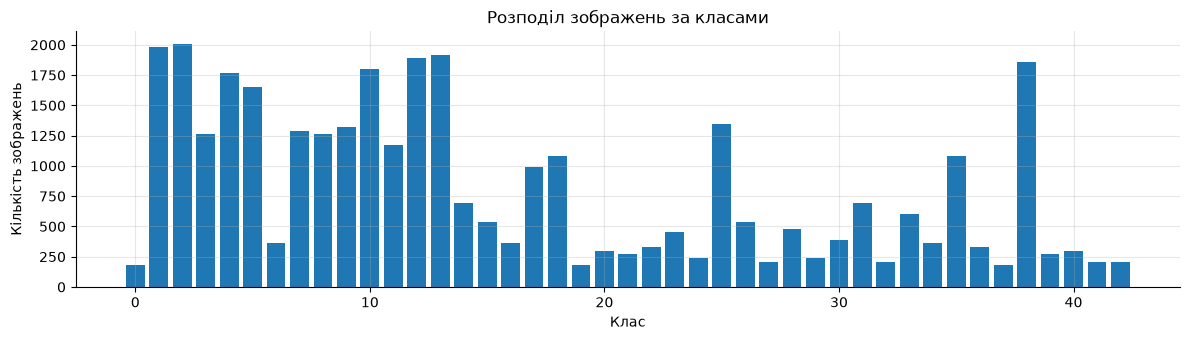

In [16]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(class_counts.index, class_counts.values)
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.set_title("Images per class")
fig.tight_layout()
saver.save(fig, "class_distribution");

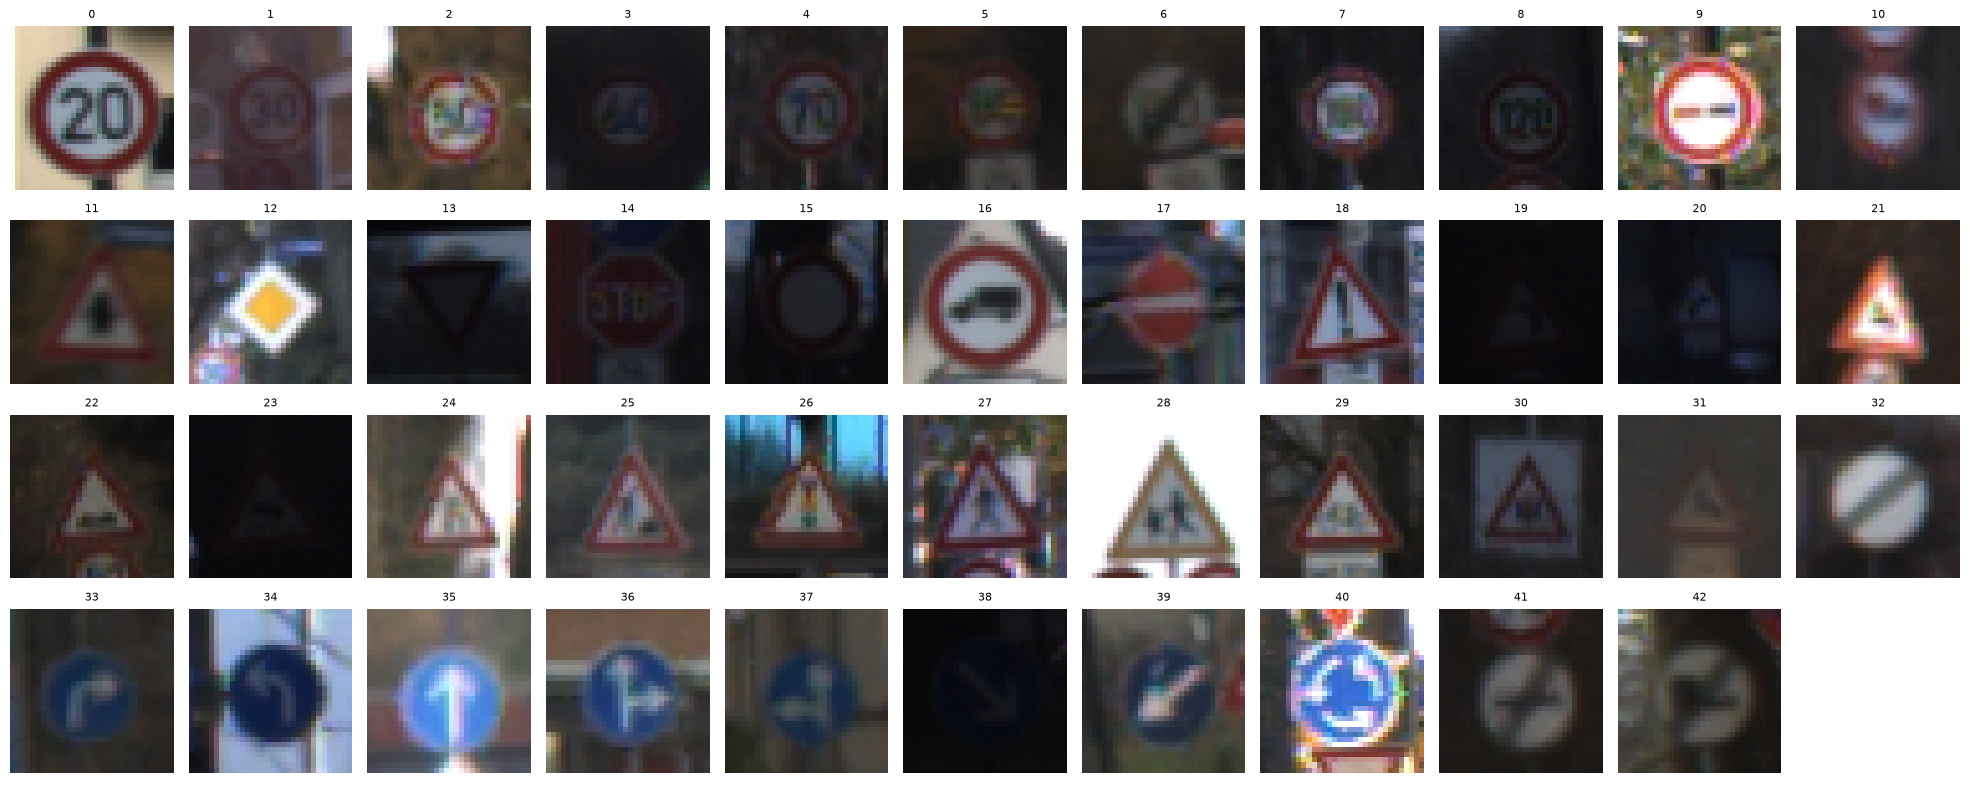

In [17]:
first_of_class = [int(np.flatnonzero(labels == label)[0]) for label in class_counts.index]
examples = torch.from_numpy(features[first_of_class]).permute(0, 3, 1, 2).float() / 255
saver.save(plot_image_grid(examples, [str(label) for label in class_counts.index], ncols=11), "samples");

In [18]:
images = torch.from_numpy(features).permute(0, 3, 1, 2).float() / 127.5 - 1
print(f"Tensor: {tuple(images.shape)} | range: [{images.min().item():.1f}, {images.max().item():.1f}]")

Тензор: (34799, 3, 32, 32) | діапазон: [-1.0, 1.0]


In [ ]:
def generator_config(batch_norm: bool) -> GeneratorConfig:
    norm = BatchNorm() if batch_norm else None
    return GeneratorConfig(
        latent_dim=LATENT_DIM,
        convT_configs=(
            ConvTransposeBlockConfig(512, kernel_size=4, stride=1, padding=0, norm=norm),
            ConvTransposeBlockConfig(256, norm=norm),
            ConvTransposeBlockConfig(128, norm=norm),
            ConvTransposeBlockConfig(3, activation=Tanh()),
        ),
    )


discriminator_config = CNNConfig(
    in_channels=3,
    input_size=(32, 32),
    conv_configs=(
        ConvBlockConfig(64, kernel_size=4, stride=2, padding=1, pool_size=1, activation=LeakyReLU()),
        ConvBlockConfig(128, kernel_size=4, stride=2, padding=1, pool_size=1, activation=LeakyReLU(), norm=BatchNorm()),
        ConvBlockConfig(256, kernel_size=4, stride=2, padding=1, pool_size=1, activation=LeakyReLU(), norm=BatchNorm()),
    ),
    linear_configs=(LinearBlockConfig(1, activation=None),),
)


def init_dcgan_weights(module: nn.Module) -> None:
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(module.weight, 0.0, 0.02)
        if module.bias is not None:
            nn.init.zeros_(module.bias)
    elif isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d)):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


models = {
    "Generator with BatchNorm": Generator(generator_config(batch_norm=True)),
    "Generator without BatchNorm": Generator(generator_config(batch_norm=False)),
    "Discriminator": CNNClassifier(discriminator_config),
}
for name, model in models.items():
    print(f"===== {name}: {sum(p.numel() for p in model.parameters()):,} parameters")
    print(model)

print("Generator output:", tuple(models["Generator with BatchNorm"](torch.zeros(2, LATENT_DIM)).shape))

In [20]:
VARIANTS: dict[str, bool] = {
    "with_bn": True,
    "without_bn": False,
}


@dataclass
class RunResult:
    task: GANTask
    history: History
    seconds: float


def run(name: str, batch_norm: bool) -> RunResult:
    seed_everything(SEED)
    generator_cfg = generator_config(batch_norm)
    generator = Generator(generator_cfg)
    discriminator = CNNClassifier(discriminator_config)
    generator.apply(init_dcgan_weights)
    discriminator.apply(init_dcgan_weights)
    task = GANTask(
        generator=generator,
        discriminator=discriminator,
        g_optimizer=partial(torch.optim.Adam, lr=LEARNING_RATE, betas=BETAS),
        d_optimizer=partial(torch.optim.Adam, lr=LEARNING_RATE, betas=BETAS),
        real_label=REAL_LABEL,
    )
    sample_z = torch.randn(NUM_SAMPLES, LATENT_DIM, generator=torch.Generator().manual_seed(SEED))
    loader = DataLoader(images, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, pin_memory=True)

    with mlflow.start_run(run_name=name):
        mlflow.log_params(
            {f"generator.{key}": value for key, value in flatten_params(generator_cfg).items()}
            | {f"discriminator.{key}": value for key, value in flatten_params(discriminator_config).items()}
            | {
                "batch_norm": batch_norm,
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
                "learning_rate": LEARNING_RATE,
                "beta1": BETAS[0],
                "real_label": REAL_LABEL,
                "weight_init": "normal(0, 0.02)",
            }
        )
        trainer = Trainer(callbacks=[
            ProgressLogger(every=1),
            MLflowLogger(),
            SampleGrid(lambda: task.generate(z=sample_z), FigureSaver(saver.directory / name), every=SAMPLE_EVERY),
        ])
        start = time.perf_counter()
        history = trainer.fit(task, loader, epochs=EPOCHS)
        seconds = time.perf_counter() - start

    return RunResult(task, history, seconds)

In [21]:
results: dict[str, RunResult] = {}
for name, batch_norm in VARIANTS.items():
    print(f"===== {name}")
    results[name] = run(name, batch_norm)

===== with_bn
Epoch 1 | train/d_loss 0.5639 train/g_loss 4.93 train/d_real 0.8117 train/d_fake 0.09921 | 9.0s
Epoch 2 | train/d_loss 0.7576 train/g_loss 3.192 train/d_real 0.7135 train/d_fake 0.1776 | 8.1s
Epoch 3 | train/d_loss 0.9184 train/g_loss 2.47 train/d_real 0.6451 train/d_fake 0.2527 | 8.1s
Epoch 4 | train/d_loss 0.9121 train/g_loss 2.041 train/d_real 0.6401 train/d_fake 0.2583 | 8.1s
Epoch 5 | train/d_loss 0.831 train/g_loss 2.109 train/d_real 0.6663 train/d_fake 0.2308 | 8.2s
Epoch 6 | train/d_loss 0.8085 train/g_loss 2.148 train/d_real 0.6754 train/d_fake 0.221 | 8.2s
Epoch 7 | train/d_loss 0.7741 train/g_loss 2.193 train/d_real 0.6883 train/d_fake 0.2098 | 7.7s
Epoch 8 | train/d_loss 0.855 train/g_loss 2.162 train/d_real 0.6751 train/d_fake 0.2233 | 7.9s
Epoch 9 | train/d_loss 0.7601 train/g_loss 2.176 train/d_real 0.6896 train/d_fake 0.2064 | 7.8s
Epoch 10 | train/d_loss 0.7943 train/g_loss 2.181 train/d_real 0.6864 train/d_fake 0.2123 | 8.0s
Epoch 11 | train/d_loss 0.790

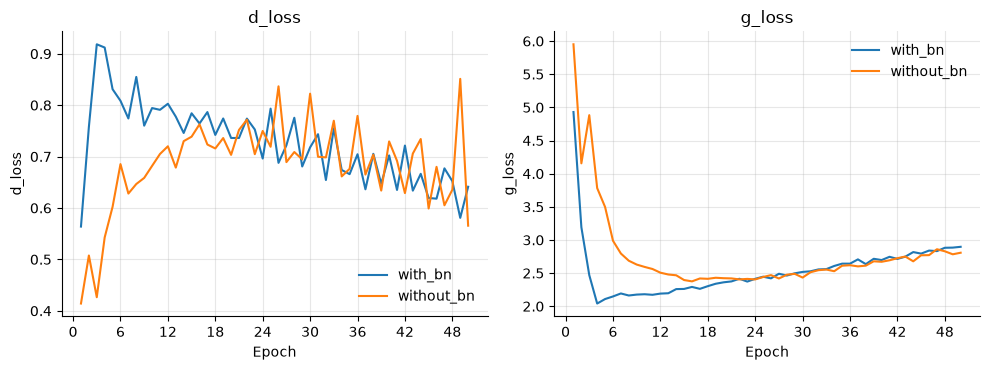

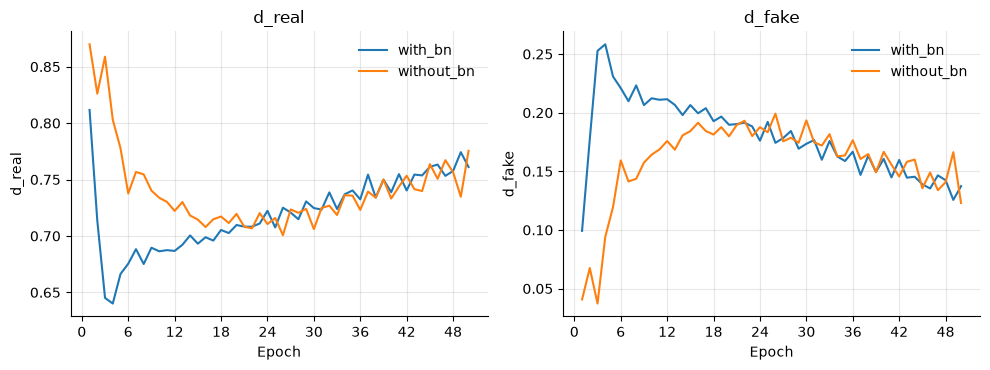

In [22]:
histories = {name: result.history for name, result in results.items()}
saver.save(plot_comparison(histories, ["d_loss", "g_loss"], splits=("train",)), "losses")
saver.save(plot_comparison(histories, ["d_real", "d_fake"], splits=("train",)), "discriminator_outputs");

In [23]:
def last_epochs_std(history: History, key: str, epochs: int = 10) -> float:
    return float(np.std(history.series(key)[1][-epochs:]))


summary = pd.DataFrame({
    name: {
        "d_loss (last epoch)": result.history.last("train/d_loss"),
        "g_loss (last epoch)": result.history.last("train/g_loss"),
        "D(x) (last epoch)": result.history.last("train/d_real"),
        "D(G(z)) (last epoch)": result.history.last("train/d_fake"),
        "std g_loss (last 10 epochs)": last_epochs_std(result.history, "train/g_loss"),
        "training time, s": result.seconds,
    }
    for name, result in results.items()
}).T
summary.to_csv(saver.directory / "summary.csv")
summary.round(4)

,d_loss (остання епоха),g_loss (остання епоха),D(x) (остання епоха),D(G(z)) (остання епоха),std g_loss (останні 10 епох),"час навчання, с"
with_bn,0.6413,2.8967,0.7611,0.1373,0.0606,395.0338
without_bn,0.5656,2.8075,0.7754,0.1230,0.0547,811.2808


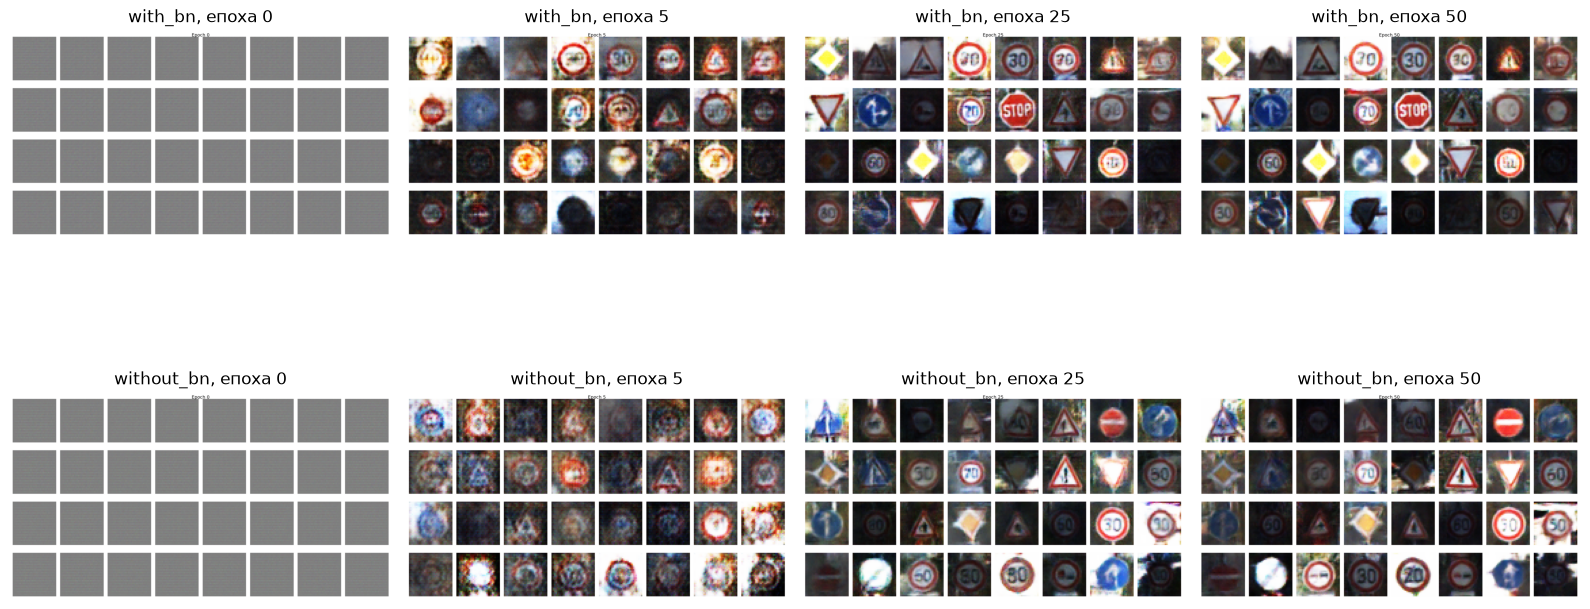

In [24]:
epochs_to_show = [0, 5, 25, EPOCHS]
fig, axes = plt.subplots(len(results), len(epochs_to_show), figsize=(4 * len(epochs_to_show), 4.4 * len(results)), squeeze=False)
for row, name in zip(axes, results):
    for ax, epoch in zip(row, epochs_to_show):
        ax.imshow(plt.imread(saver.directory / name / f"samples_epoch_{epoch:03d}.png"))
        ax.set_title(f"{name}, epoch {epoch}")
        ax.axis("off")
fig.tight_layout()
saver.save(fig, "progress");

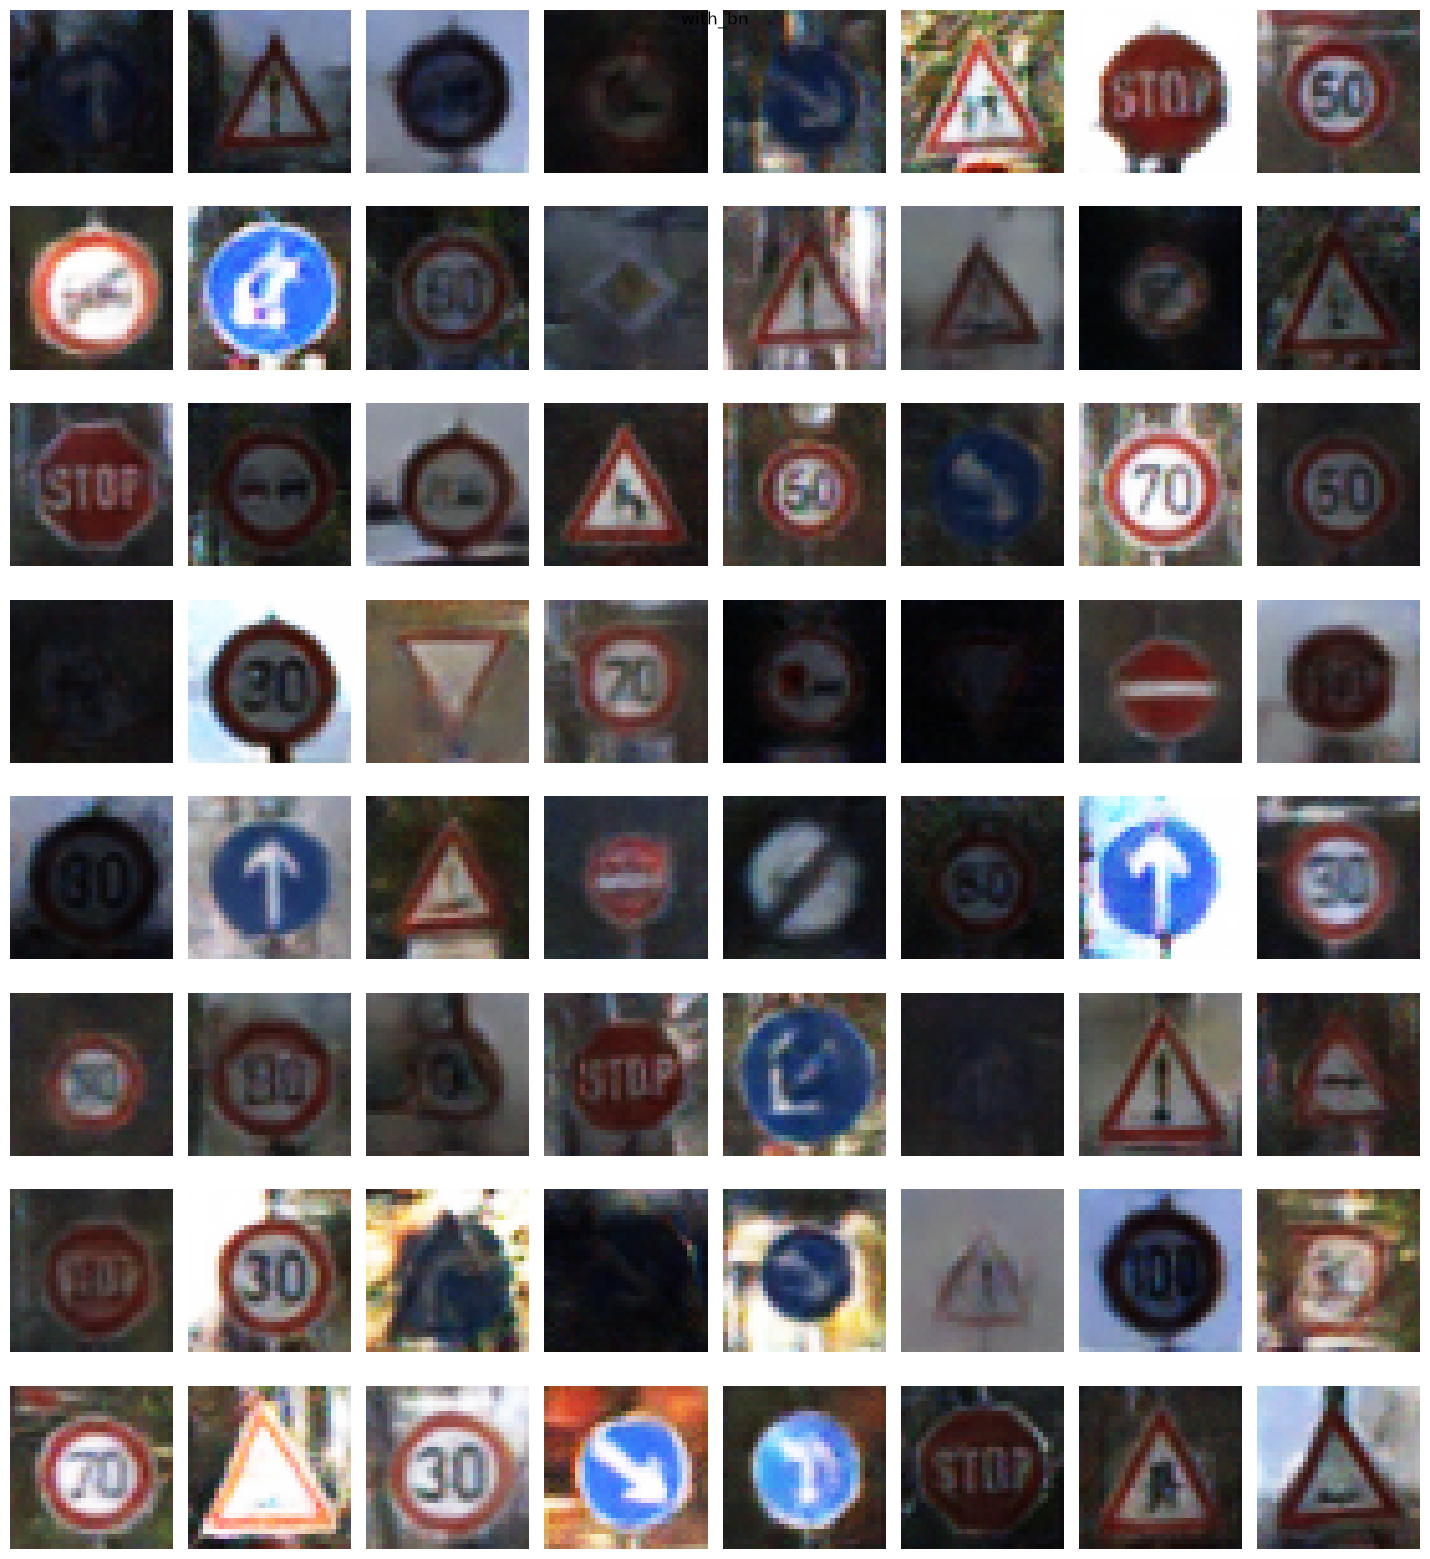

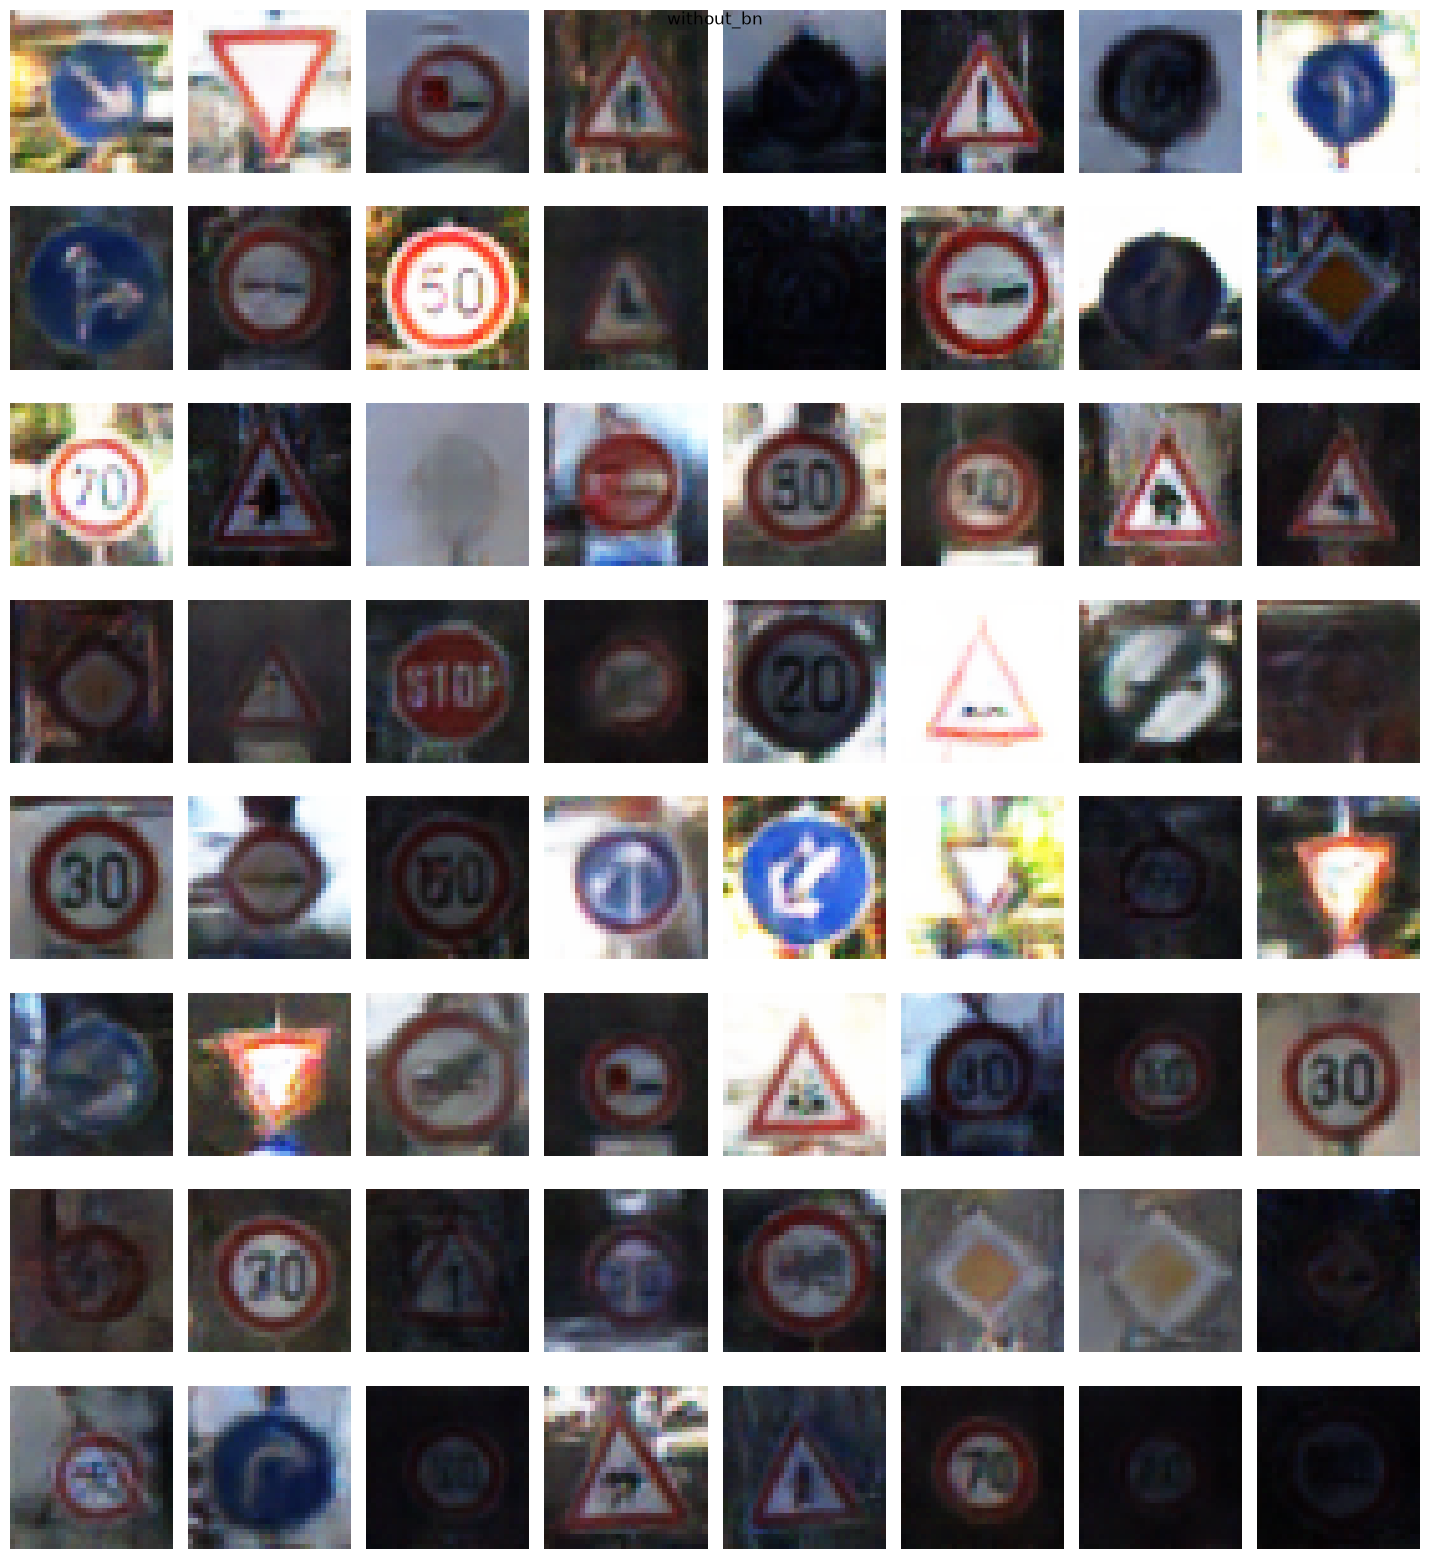

In [25]:
final_noise = torch.randn(64, LATENT_DIM, generator=torch.Generator().manual_seed(SEED + 1))
for name, result in results.items():
    fig = plot_image_grid(result.task.generate(z=final_noise), ncols=8)
    fig.suptitle(name)
    saver.save(fig, f"final_{name}")

In [26]:
def diversity(batch: torch.Tensor) -> float:
    return torch.pdist(batch.flatten(1)).mean().item()


real_indices = torch.randperm(len(images), generator=torch.Generator().manual_seed(SEED))[:512]
pd.Series(
    {"real": diversity((images[real_indices] + 1) / 2)}
    | {name: diversity(result.task.generate(512)) for name, result in results.items()},
    name="mean pairwise distance between images",
).round(3)

реальні       19.144
with_bn       18.641
without_bn    19.193
Name: середня попарна відстань між зображеннями, dtype: float64